In [1]:
!pip install pyblp
import numpy as np
import pandas as pd
import pyblp
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 54.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pyblp]


In [2]:

product_data = pd.read_excel("data_HA_2026.xlsx")
product_data = product_data.sort_values(["market_ids", "product_ids"]).reset_index(drop=True)
product_data.head()

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,prices,shares,market_ids,firm_ids,product_ids,quality,satellite,wired,demand_instruments0
0,2.636681,0.469490,0,1,1,0.921656,1,0,0.072425
1,2.812415,0.237731,0,2,2,1.834763,1,0,0.548527
2,2.417776,0.038745,0,3,3,0.762334,0,1,0.868230
3,2.321038,0.163560,0,4,4,1.399432,0,1,0.135893
4,2.534516,0.114659,1,1,1,0.082587,1,0,0.235976


#Task 1

In [3]:
#a
market0 = product_data[product_data['market_ids'] == 0]
outside_share_0 = 1 - market0['shares'].sum()
print(outside_share_0)

0.09047369917765513


In [4]:
# b
market0_sat = market0[market0['satellite'] == 1]
share_1_within_sat = market0_sat.loc[market0_sat['product_ids'] == 1, 'shares'].iloc[0] / market0_sat['shares'].sum()
print(share_1_within_sat)

0.663852271845465


In [5]:
# c
avg_price_satellite = market0[market0['satellite'] == 1]['prices'].mean()
avg_price_wired = market0[market0['wired'] == 1]['prices'].mean()
print("Avg price satellite:", avg_price_satellite)
print("Avg price wired:", avg_price_wired)

Avg price satellite: 2.7245480816183614
Avg price wired: 2.369407011191835


#Answer:
a) The share of consumers not buying any of the 4 goods in market 0 is approximately **0,09** \
b) For market 0, the share of good 1 within the group of all satellite services goods is approximately **0,66** \
c) For market 0, the average price of satellite services is **2,72** and for wired services it is **2,37**

# Task 2

In [6]:
logit_formulation = pyblp.Formulation('0 + quality + satellite + wired + prices')
print(logit_formulation)

quality + satellite + wired + prices


In [7]:
# a
problem_IV = pyblp.Problem(logit_formulation, product_data)
logit_results_IV = problem_IV.solve()
logit_results_IV

Initializing the problem ...
Initialized the problem after 00:00:00.

Dimensions:
 T     N     F    K1    MD 
----  ----  ---  ----  ----
1000  4000   4    4     4  

Formulations:
     Column Indices:           0         1        2      3   
--------------------------  -------  ---------  -----  ------
X1: Linear Characteristics  quality  satellite  wired  prices
Solving the problem ...
Updating the weighting matrix ...
Computed results after 00:00:00.

Problem Results Summary:
GMM     Objective    Clipped  Weighting Matrix  Covariance Matrix
Step      Value      Shares   Condition Number  Condition Number 
----  -------------  -------  ----------------  -----------------
 1    +8.725207E-25     0      +2.244862E+01      +1.663582E+03  

Estimating standard errors ...
Computed results after 00:00:00.

Problem Results Summary:
GMM     Objective    Clipped  Weighting Matrix  Covariance Matrix
Step      Value      Shares   Condition Number  Condition Number 
----  -------------  ------- 

Problem Results Summary:
GMM     Objective    Clipped  Weighting Matrix  Covariance Matrix
Step      Value      Shares   Condition Number  Condition Number 
----  -------------  -------  ----------------  -----------------
 2    +3.261871E-25     0      +2.322815E+01      +1.663582E+03  

Cumulative Statistics:
Computation   Objective 
   Time      Evaluations
-----------  -----------
 00:00:00         2     

Beta Estimates (Robust SEs in Parentheses):
    quality         satellite          wired           prices     
---------------  ---------------  ---------------  ---------------
 +9.431118E-01    +4.065845E+00    +3.030266E+00    -1.988268E+00 
(+2.543810E-02)  (+1.520574E-01)  (+1.454054E-01)  (+5.589192E-02)

#Answer (a)
The estimated parametrs in plain logit with instrument variable for price are:\
alpha (price coefficient) = 1,99 \
beta 1 (quality coefficient) = 0,94 \
beta 2 (satellite coefficient) = 4,07 \
beta 3 (wired coefficient) = 3,03

Satellite services provide on average more utility at the baseline level of quality compared to wired services (4,07> 3,03)


In [8]:
# b
product_data_OLS = product_data.copy()
product_data_OLS["demand_instruments0"] = product_data_OLS["prices"]

problem_OLS = pyblp.Problem(logit_formulation, product_data_OLS)
logit_results_OLS = problem_OLS.solve()
logit_results_OLS

Initializing the problem ...
Initialized the problem after 00:00:00.

Dimensions:
 T     N     F    K1    MD 
----  ----  ---  ----  ----
1000  4000   4    4     4  

Formulations:
     Column Indices:           0         1        2      3   
--------------------------  -------  ---------  -----  ------
X1: Linear Characteristics  quality  satellite  wired  prices
Solving the problem ...
Updating the weighting matrix ...
Computed results after 00:00:00.

Problem Results Summary:
GMM     Objective    Clipped  Weighting Matrix  Covariance Matrix
Step      Value      Shares   Condition Number  Condition Number 
----  -------------  -------  ----------------  -----------------
 1    +9.307494E-24     0      +8.167860E+02      +1.217868E+03  

Estimating standard errors ...
Computed results after 00:00:00.

Problem Results Summary:
GMM     Objective    Clipped  Weighting Matrix  Covariance Matrix
Step      Value      Shares   Condition Number  Condition Number 
----  -------------  ------- 

Problem Results Summary:
GMM     Objective    Clipped  Weighting Matrix  Covariance Matrix
Step      Value      Shares   Condition Number  Condition Number 
----  -------------  -------  ----------------  -----------------
 2    +3.320633E-24     0      +6.351156E+02      +1.217868E+03  

Cumulative Statistics:
Computation   Objective 
   Time      Evaluations
-----------  -----------
 00:00:00         2     

Beta Estimates (Robust SEs in Parentheses):
    quality         satellite          wired           prices     
---------------  ---------------  ---------------  ---------------
 +8.510123E-01    +1.675875E+00    +7.529366E-01    -1.094884E+00 
(+2.327157E-02)  (+1.198236E-01)  (+1.140803E-01)  (+4.435551E-02)

# Answer (b)
In OLS with price as its own instrument: \
alpha = 1,09 \
beta 1 = 0,85 \
beta 2 = 1,68 \
beta 3 = 0,75

The OLS price coefficient is biased towards zero, so alpha is underestimated. Its less negative than the true coefficient because price is endogenous (price and good-market-level shock are positively correlated)


In [9]:
# b
alpha_OLS = -logit_results_OLS.beta[3].item()
alpha_IV = -logit_results_IV.beta[3].item()

print(alpha_OLS)
print(alpha_IV)
print(alpha_OLS - alpha_IV)

1.0948842013071403
1.9882684783157951
-0.8933842770086549


Computing elasticities with respect to prices ...
Finished after 00:00:01.

          1         2         3         4
1 -2.781160  1.329352  0.186255  0.754804
2  2.461271 -4.262484  0.186255  0.754804
3  2.461271  1.329352 -4.620933  0.754804
4  2.461271  1.329352  0.186255 -3.860042


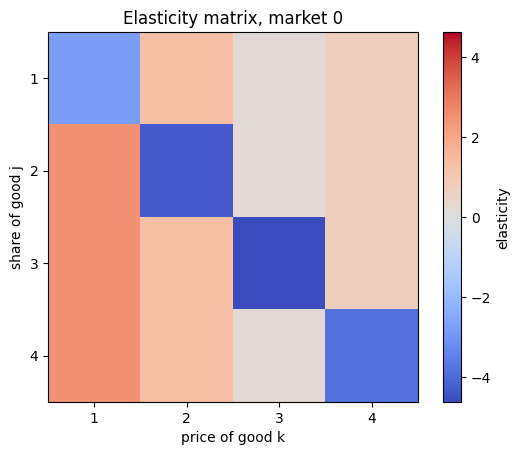

0.7548040802957098


In [10]:
elasticities = logit_results_IV.compute_elasticities()
market_0_mask = product_data["market_ids"] == 0
elasticities_m0 = elasticities[market_0_mask]

goods = [1, 2, 3, 4]
elasticity_df = pd.DataFrame(elasticities_m0, index=goods, columns=goods)
print(elasticity_df)

plt.imshow(elasticity_df, cmap="coolwarm", vmin=-abs(elasticities_m0).max(), vmax=abs(elasticities_m0).max())
plt.colorbar(label="elasticity")
plt.xticks(range(4), goods)
plt.yticks(range(4), goods)
plt.xlabel("price of good k")
plt.ylabel("share of good j")
plt.title("Elasticity matrix, market 0")
plt.show()

elast_2_4 = elasticity_df.values[1, 3]
print(elast_2_4)

#Answer (c):
The elasticity of the market share of good 2 with respect to the price of good 4 in market 0 is approximately 0.755. This means that if the price of a wired service increases by 1%, the market share of a satellite service increases by about 0.75%. The elasticity is positive because the goods are substitutes

In [11]:
# d
delta_m0 = logit_results_IV.delta[(product_data["market_ids"] == 0).values].flatten()
epsilon = np.array([0.8, -1, 0, 1.5, -2])

u = np.insert(delta_m0 + epsilon[1:], 0, epsilon[0])

print("Utilities:", u)
print("Alice chooses option:", u.argmax())

Utilities: [ 0.8         0.64658871  0.9660798   0.65194508 -1.40787952]
Alice chooses option: 2


#Answer (d):
Alice chooses good 2 (a satellite service). Its utility = 0,966

In [12]:
# e
market0 = product_data[product_data["market_ids"] == 0]
satellite0 = market0[market0["satellite"] == 1]
x_Y = satellite0["quality"].mean()
p_Y = satellite0["prices"].mean()

beta = logit_results_IV.beta.flatten()
delta_Y = beta[0] * x_Y + beta[1] + beta[3] * p_Y

delta_m0 = logit_results_IV.delta[(product_data["market_ids"] == 0).values].flatten()
share_Y = np.exp(delta_Y) / (1 + np.exp(delta_m0).sum() + np.exp(delta_Y))
print(share_Y)

0.07913349448242067


# Answer (e):
The market share of Y = 0,079

#Task 3

#Answer (a):
In the dataset the number of goods in each nest across all markets is the same  (each market has exactly two sattilite and two wired goods), so the instrument would be constant. A constant cannot be a valid instrument. First, it has no variation across goods and markets, so it cannot explain any variation in the within-nest share and it gives no information to estimate the nesting parameter. Second, there is no constant in the utility, but satellite + wired = 1 for all inside goods, so the number of goods in the nest (equal to 2 for every good) is just 2*(satellite + wired). This is a linear combination of the exogenous variables that are already in the model, so it is perfectly collinear with them and is not a new excluded instrument. Because of this, the parameter rho would not be identified

In [13]:
# b
product_data['nest_id'] = product_data['satellite']
product_data['nest_quality_sum'] = product_data.groupby(['market_ids', 'nest_id'])['quality'].transform('sum')
product_data['demand_instruments1'] = product_data['nest_quality_sum'] - product_data['quality']
product_data = product_data.drop(columns=['nest_quality_sum', 'nest_id'])
product_data[product_data['market_ids'] == 0][['product_ids', 'quality', 'satellite', 'demand_instruments1']]

,product_ids,quality,satellite,demand_instruments1
0,1,0.921656,1,1.834763
1,2,1.834763,1,0.921656
2,3,0.762334,0,1.399432
3,4,1.399432,0,0.762334


In [23]:
# c
product_data_nested = product_data.copy()
product_data_nested["nesting_ids"] = product_data_nested["satellite"]

nested_problem = pyblp.Problem(logit_formulation, product_data_nested)
nested_results = nested_problem.solve(rho=0.5)
print(nested_results)

Initializing the problem ...
Initialized the problem after 00:00:00.

Dimensions:
 T     N     F    K1    MD    H 
----  ----  ---  ----  ----  ---
1000  4000   4    4     6     2 

Formulations:
     Column Indices:           0         1        2      3   
--------------------------  -------  ---------  -----  ------
X1: Linear Characteristics  quality  satellite  wired  prices
Solving the problem ...

Rho Initial Values:
 All Groups  
-------------
+5.000000E-01

Rho Lower Bounds:
 All Groups  
-------------
+0.000000E+00

Rho Upper Bounds:
 All Groups  
-------------
+9.900000E-01

Starting optimization ...

GMM   Computation  Optimization   Objective   Fixed Point  Contraction  Clipped    Objective      Objective      Projected                 
Step     Time       Iterations   Evaluations  Iterations   Evaluations  Shares       Value       Improvement   Gradient Norm      Theta    
----  -----------  ------------  -----------  -----------  -----------  -------  -------------  -----

#Answer (c):
The estimate of rho is 0,08 with a standard error = 0,06. T-statistic is approximately 1,33 < 1,96, so estimate is not statistically significant on 5% level. The correlation of individual shocks among same-nest goods is weak

In [24]:
#d
nested_elasticities = nested_results.compute_elasticities(market_id=0)
print(nested_elasticities)

print(nested_elasticities[1, 3])
print(elasticities[1, 3])
print(pd.DataFrame(nested_elasticities, index=[1, 2, 3, 4], columns=[1, 2, 3, 4]))

Computing elasticities with respect to prices ...
Finished after 00:00:00.

[[-2.79806469  1.42341567  0.17760508  0.71975005]
 [ 2.63542886 -4.3722172   0.17760508  0.71975005]
 [ 2.34696648  1.26761489 -4.7284728   1.02900206]
 [ 2.34696648  1.26761489  0.25391591 -3.75403456]]
0.7197500473626477
0.7548040802957098
          1         2         3         4
1 -2.798065  1.423416  0.177605  0.719750
2  2.635429 -4.372217  0.177605  0.719750
3  2.346966  1.267615 -4.728473  1.029002
4  2.346966  1.267615  0.253916 -3.754035


#Answer (d):
The elasticity of the share of good 2 with respect to the price of good 4 in market 0 in the nested logit is 0,7198. In plain logit it is 0,755


#Task 4

#Answer (a):
In mixed logit we need at least one more instrument compared to nested logit because mixed logit has more parameters to estimate (the standard deviations of the random coefficients beta). In GMM, the number of instruments must be at least as large as the number of parameters

In [15]:
# b
product_data['market_quality_sum'] = product_data.groupby('market_ids')['quality'].transform('sum')
product_data['demand_instruments2'] = product_data['market_quality_sum'] - product_data['quality']
product_data = product_data.drop(columns=['market_quality_sum'])

product_data[product_data['market_ids'] == 0][['product_ids', 'quality', 'demand_instruments2']]

,product_ids,quality,demand_instruments2
0,1,0.921656,3.996530
1,2,1.834763,3.083422
2,3,0.762334,4.155852
3,4,1.399432,3.518753


In [16]:
#c
mc_integration = pyblp.Integration('monte_carlo', size=100, specification_options={'seed': 0})
mc_integration

Configured to construct nodes and weights with Monte Carlo simulation with options {seed: 0}.

In [17]:
bfgs_opt = pyblp.Optimization('bfgs', {'gtol': 1e-6})

In [18]:
X1_formulation = pyblp.Formulation('0 + quality + satellite + wired + prices')
X2_formulation = pyblp.Formulation('0 + satellite + wired')

product_formulations = (X1_formulation, X2_formulation)
product_formulations

(quality + satellite + wired + prices, satellite + wired)

In [19]:
product_data_mixed = product_data.copy()
mixed_problem = pyblp.Problem((X1_formulation, X2_formulation), product_data_mixed, integration=mc_integration)

mixed_results = mixed_problem.solve(sigma=np.diag([1, 1]), optimization=bfgs_opt, method='1s')
print(mixed_results)

mean_satellite, mean_wired = mixed_results.beta[1].item(), mixed_results.beta[2].item()
sd_satellite, sd_wired = abs(mixed_results.sigma[0, 0]), abs(mixed_results.sigma[1, 1])

print(f"satellite: mean = {mean_satellite:.4f}, sd = {sd_satellite:.4f}")
print(f"wired:     mean = {mean_wired:.4f}, sd = {sd_wired:.4f}")

ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x7d09520f5060>>)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
    ...<3 lines>...
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
        msg_or_type,
    ...<3 lines>...
        metadata=metadata,
    )
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/usr/local/lib/python3

GMM   Computation  Optimization   Objective   Fixed Point  Contraction  Clipped    Objective      Objective      Gradient                                 
Step     Time       Iterations   Evaluations  Iterations   Evaluations  Shares       Value       Improvement       Norm                  Theta            
----  -----------  ------------  -----------  -----------  -----------  -------  -------------  -------------  -------------  ----------------------------
 1     00:00:05         0             1          6957         21381        0     +8.182246E-01                 +2.438204E+00  +1.000000E+00, +1.000000E+00
 1     00:00:04         0             2          5058         15869        0     +3.787259E+00                 +3.217119E+00  +2.730120E-01, +2.988663E-01
 1     00:00:07         0             3          6704         20680        0     +5.423270E-01  +2.758976E-01  +4.315986E-02  +8.784748E-01, +8.827967E-01
 1     00:00:05         1             4          6707         20702   

ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x7d09520f5060>>)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
    ...<3 lines>...
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
        msg_or_type,
    ...<3 lines>...
        metadata=metadata,
    )
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/usr/local/lib/python3

 1     00:00:07         3            11          6727         20706        0     +4.705407E-01  +1.661298E-03  +9.087026E-01  +1.217805E+00, +5.067732E-01
 1     00:00:05         3            12          6720         20713        0     +4.640837E-01  +6.457026E-03  +8.715463E-01  +1.220747E+00, +4.942704E-01
 1     00:00:07         3            13          6714         20695        0     +4.411018E-01  +2.298191E-02  +7.435606E-01  +1.232515E+00, +4.442593E-01
 1     00:00:05         4            14          6674         20575        0     +3.945897E-01  +4.651213E-02  +4.315112E-01  +1.255188E+00, +3.094890E-01
 1     00:00:05         5            15          6667         20561        0     +3.727129E-01  +2.187680E-02  +1.408737E-01  +1.260513E+00, +1.902963E-01
 1     00:00:07         6            16          6660         20571        0     +3.698067E-01  +2.906144E-03  +4.517131E-02  +1.260548E+00, +1.403619E-01
 1     00:00:05         7            17          6689         20667   

ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x7d09520f5060>>)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
    ...<3 lines>...
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
        msg_or_type,
    ...<3 lines>...
        metadata=metadata,
    )
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/usr/local/lib/python3

 1     00:00:05         8            19          6678         20628        0     +3.696033E-01  +2.874785E-05  +3.728257E-03  +1.258875E+00, +1.243041E-01
 1     00:00:05         9            20          6673         20605        0     +3.696025E-01  +7.922611E-07  +6.145455E-05  +1.259049E+00, +1.250525E-01
 1     00:00:08         10           21          6676         20611        0     +3.696025E-01  +1.539273E-10  +2.126144E-07  +1.259053E+00, +1.250597E-01

Optimization completed after 00:01:55.
Computing the Hessian and estimating standard errors ...
Computed results after 00:00:27.

Problem Results Summary:
GMM     Objective      Gradient         Hessian         Hessian     Clipped  Weighting Matrix  Covariance Matrix
Step      Value          Norm       Min Eigenvalue  Max Eigenvalue  Shares   Condition Number  Condition Number 
----  -------------  -------------  --------------  --------------  -------  ----------------  -----------------
 1    +3.696025E-01  +2.126144E-07  +1.1

#Answer(c):
Estimated means and standard deviations of the coefficients in the population:
β2 (satellite): mean = 4,196, standard deviation = 1,259
β3 (wired): mean = 3,236, standard deviation = 0,125

Satellite services have higher variance of the utility from the baseline quality level. It means that consumers differ a lot in how much they value satellite TV and differ less in how much they value wired TV.

Wired TV is a more standardized product because a cable is available in most places and works in the same way for everyone, but sattilite TV requires a dish installed with a clear view of the sky, so it is much more useful in rural areas and for people living in houses than for people in apartment buildings.So some consumers value it a lot and some almost do not value it

In [20]:
#d
beta_satellite = mixed_results.beta[1].item()
alpha = -mixed_results.beta[3].item()

mean_wtp = beta_satellite / alpha
print(mean_wtp)

2.0123687556936836


#Answer (d)
Average willingness-to-pay across all consumers in the population = 2,012

In [21]:
#e
beta_satellite = mixed_results.beta[1].item()
sigma_satellite = mixed_results.sigma[0, 0]
alpha = -mixed_results.beta[3].item()

In [22]:
wtp_mean = beta_satellite / alpha
wtp_sd = sigma_satellite / alpha

wtp_lower = wtp_mean - 1.96 * wtp_sd
wtp_upper = wtp_mean + 1.96 * wtp_sd

print(wtp_lower, wtp_upper)

0.8287309114876618 3.1960065998997056


#Answer (e):
WTP_l is approximately 0,83 and WTP_h is approximately 3,20.
Thus, 95% of consumers are willing to pay between 0,83 and 3,20 for a baseline-quality satellite product